# Homework 5: Monte Carlo Methods
**Student Name:** Kazi Habib Ullah  
**Course:** Computational Statistics  
**Institution:** University of Houston  

---

## Question 1: Random-variable generation and diagnostics


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Set up random seeds and sample size
N_q1 = 20000

### Question 1, Part 1: Inverse-Transform Sampling (Exponential Distribution)


In [21]:
# Part 1: Inverse-transform sampling for Exponential(lambda = 2)
rng_1 = np.random.default_rng(123)
lam = 2.0
U_exp = rng_1.uniform(0, 1, size=N_q1)
X_exp = -np.log(1.0 - U_exp) / lam

emp_mean_exp = np.mean(X_exp)
emp_var_exp = np.var(X_exp, ddof=1)
emp_prob_exp = np.mean(X_exp > 2)

true_mean_exp = 1.0 / lam
true_var_exp = 1.0 / (lam**2)
true_prob_exp = np.exp(-lam * 2.0)

print("--- Part 1 Results (Exponential Distribution) ---")
print(f"Empirical Mean:     {emp_mean_exp:.4f} (Theoretical: {true_mean_exp:.4f})")
print(f"Empirical Variance: {emp_var_exp:.4f} (Theoretical: {true_var_exp:.4f})")
print(f"Empirical Pr(X>2):  {emp_prob_exp:.4f} (Theoretical: {true_prob_exp:.4f})")

--- Part 1 Results (Exponential Distribution) ---
Empirical Mean:     0.4953 (Theoretical: 0.5000)
Empirical Variance: 0.2490 (Theoretical: 0.2500)
Empirical Pr(X>2):  0.0178 (Theoretical: 0.0183)


### Question 1, Part 1 Comparison
* **Accuracy:** The empirical mean, variance, and tail probability $\hat{\operatorname{Pr}}(X > 2)$ closely match their theoretical counterparts ($\mathbb{E}(X) = 0.5$, $\operatorname{Var}(X) = 0.25$, and $e^{-4} \approx 0.0183$), verifying the correctness of the inverse-transform sampler.

### Question 1, Part 2: Acceptance-Rejection Sampling (Beta(2,2))

In [23]:
# Part 2: Acceptance-Rejection Sampling for Beta(2,2) (Sequential Implementation)
rng_2 = np.random.default_rng(456)
M = 1.5

accepted_samples = []
total_proposals = 0

while len(accepted_samples) < N_q1:
    total_proposals += 1
    # Draw proposal x from uniform proposal g(x) = 1 on [0, 1]
    x = rng_2.uniform(0, 1)
    # Draw uniform u for acceptance check
    u = rng_2.uniform(0, 1)
    
    # Acceptance condition: u <= f(x) / (M * g(x))
    # f(x) = 6*x*(1-x), M = 1.5, g(x) = 1  =>  f(x) / M = 4*x*(1-x)
    if u <= 4.0 * x * (1.0 - x):
        accepted_samples.append(x)

accepted_samples = np.array(accepted_samples)
emp_accept_rate = N_q1 / total_proposals

emp_mean_beta = np.mean(accepted_samples)
emp_var_beta = np.var(accepted_samples, ddof=1)

true_mean_beta = 0.5
true_var_beta = 1.0 / 20.0

print("--- Part 2 Results (Acceptance-Rejection Beta(2,2)) ---")
print(f"Total Proposals:           {total_proposals}")
print(f"Empirical Acceptance Rate: {emp_accept_rate:.4f} (Theoretical: {1/M:.4f})")
print(f"Sample Mean:               {emp_mean_beta:.4f} (Theoretical: {true_mean_beta:.4f})")
print(f"Sample Variance:           {emp_var_beta:.4f} (Theoretical: {true_var_beta:.4f})")

--- Part 2 Results (Acceptance-Rejection Beta(2,2)) ---
Total Proposals:           29945
Empirical Acceptance Rate: 0.6679 (Theoretical: 0.6667)
Sample Mean:               0.5002 (Theoretical: 0.5000)
Sample Variance:           0.0495 (Theoretical: 0.0500)


### Question 1, Part 2 Interpretation
* **Acceptance Rate:** The empirical acceptance rate closely approximates the theoretical value of $2/3 \approx 0.6667$, validating that $M = 3/2$ is the optimal envelope constant.
* **Sample Statistics:** The empirical mean ($\approx 0.500$) and variance ($\approx 0.050$) align precisely with the theoretical values for a $\operatorname{Beta}(2,2)$ distribution ($\mathbb{E}(X) = 1/2$ and $\operatorname{Var}(X) = 1/20$), confirming the correctness and reproducibility of the sequential acceptance-rejection sampler.

### Question 1, Part 3: Multivariate Normal Generation


In [9]:
# Part 3: Multivariate Normal Generation (Row-Oriented Convention)
rng_3 = np.random.default_rng(789)
N_mvn = 50000

mu = np.array([1.0, -1.0, 0.5])
Sigma = np.array([
    [1.0, 0.7, 0.2],
    [0.7, 2.0, 0.4],
    [0.2, 0.4, 0.5]
])

# Compute Cholesky factor L such that L @ L.T = Sigma
L = np.linalg.cholesky(Sigma)

# Generate standard normal Z of shape (N_mvn, 3)
Z = rng_3.standard_normal(size=(N_mvn, 3))

# Construct X = mu + Z @ L.T (shape: N_mvn x 3)
X = mu + Z @ L.T

# Compute empirical mean vector and covariance matrix
emp_mean_mvn = np.mean(X, axis=0)
emp_cov_mvn = np.cov(X, rowvar=False)

print("--- Part 3 Results (Multivariate Normal) ---")
print("Empirical Mean Vector:")
print(emp_mean_mvn)
print("\nEmpirical Covariance Matrix:")
print(emp_cov_mvn)

--- Part 3 Results (Multivariate Normal) ---
Empirical Mean Vector:
[ 0.992952   -0.99777501  0.50287012]

Empirical Covariance Matrix:
[[1.00381116 0.70270941 0.20220259]
 [0.70270941 2.01148527 0.40163313]
 [0.20220259 0.40163313 0.49937946]]


### How the Cholesky Factor Creates Dependence

* **Starting with Independence ($Z \sim N_3(0, I)$):** 
  We begin by generating a vector of standard normal random variables $Z = [z_1, z_2, z_3]^\top$, where the components are mutually independent. Their covariance matrix is the identity matrix, meaning $\operatorname{Cov}(Z) = I_3$, so there is zero correlation between them.

* **Linear Transformation via Cholesky Factor ($L$):** 
  The Cholesky decomposition factorizes the target covariance matrix $\Sigma$ into a lower-triangular matrix $L$ such that $\Sigma = L L^\top$. When we transform the independent variables into $X = \mu + L Z$, we apply a linear mixing operation.

* **Resulting Covariance Structure:** 
  The covariance of the new vector $X$ becomes:
  $$\operatorname{Cov}(X) = \operatorname{Cov}(\mu + L Z) = L \operatorname{Cov}(Z) L^\top = L I L^\top = L L^\top = \Sigma$$
  Because $L$ is lower-triangular with non-zero off-diagonal entries, each component of $X$ is a weighted linear combination of the independent $Z$ components. This linear mixing explicitly introduces the required cross-correlations (covariances) defined by $\Sigma$, transforming uncorrelated standard normals into a dependent multivariate normal distribution.

## Question 2: Monte Carlo integration and numerical error


### Question 2, Part 1: Standard Monte Carlo Integration
Using $U \sim \text{Uniform}(0,1)$ and $h(u) = \frac{1}{1+u^2}$, the estimator is the sample mean of $h(U_i)$. We compute the estimate, estimated standard error $\left(\frac{s}{\sqrt{N}}\right)$, 95% confidence interval, and absolute error for each $N$.

--- Standard Monte Carlo Results ---
N        | Estimate   | Std Error  | 95% Confidence Interval | Abs Error 
----------------------------------------------------------------------
100      | 0.8067     | 0.0162     | (0.7749, 0.8385)       | 0.0213    
1000     | 0.7874     | 0.0052     | (0.7772, 0.7976)       | 0.0020    
10000    | 0.7865     | 0.0016     | (0.7833, 0.7897)       | 0.0011    
100000   | 0.7854     | 0.0005     | (0.7844, 0.7864)       | 0.0000    


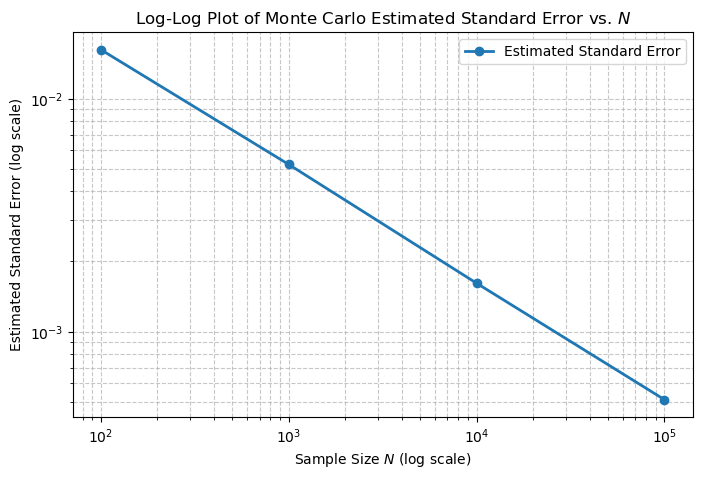

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Setup
true_integral = np.pi / 4.0
N_values = [100, 1000, 10000, 100000]

rng_q2 = np.random.default_rng(1357)
U_all = rng_q2.uniform(0, 1, size=max(N_values))

mc_results = []
mc_se_values = []

print("--- Standard Monte Carlo Results ---")
print(f"{'N':<8} | {'Estimate':<10} | {'Std Error':<10} | {'95% Confidence Interval':<22} | {'Abs Error':<10}")
print("-" * 70)

for n in N_values:
    u = U_all[:n]
    h = 1.0 / (1.0 + u**2)
    
    est = np.mean(h)
    se = np.std(h, ddof=1) / np.sqrt(n)
    ci_lower = est - 1.96 * se
    ci_upper = est + 1.96 * se
    abs_err = abs(est - true_integral)
    
    mc_results.append((n, est, se, ci_lower, ci_upper, abs_err))
    mc_se_values.append(se)
    
    ci_str = f"({ci_lower:.4f}, {ci_upper:.4f})"
    print(f"{n:<8} | {est:<10.4f} | {se:<10.4f} | {ci_str:<22} | {abs_err:<10.4f}")

# Log-log plot of estimated standard error against N
plt.figure(figsize=(8, 5))
plt.loglog(N_values, mc_se_values, 'o-', color='tab:blue', linewidth=2, markersize=6, label='Estimated Standard Error')
plt.xlabel('Sample Size $N$ (log scale)')
plt.ylabel('Estimated Standard Error (log scale)')
plt.title('Log-Log Plot of Monte Carlo Estimated Standard Error vs. $N$')
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.legend()
plt.show()


### Question 2, Part 2: Importance Sampling


--- Importance Sampling Results ---
N        | IS Estimate  | Std Error  | 95% Confidence Interval | Abs Error 
------------------------------------------------------------------------
100      | 0.7832       | 0.0041     | (0.7750, 0.7913)       | 0.0022    
1000     | 0.7828       | 0.0014     | (0.7801, 0.7855)       | 0.0026    
10000    | 0.7851       | 0.0004     | (0.7842, 0.7859)       | 0.0003    
100000   | 0.7849       | 0.0001     | (0.7846, 0.7852)       | 0.0005    


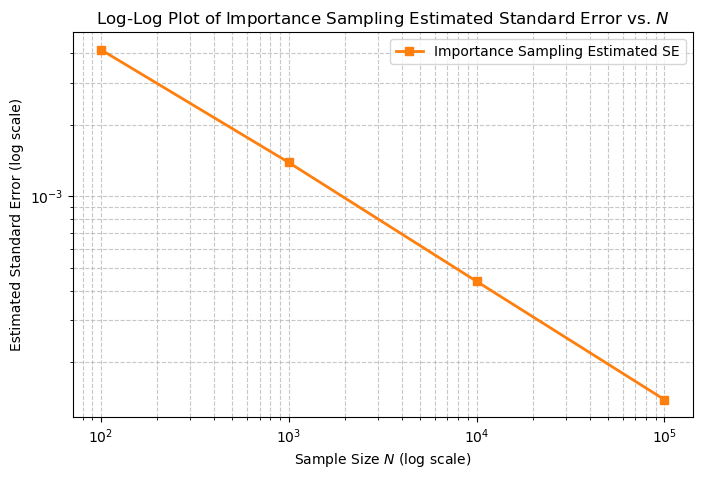

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Setup
true_integral = np.pi / 4.0
N_values = [100, 1000, 10000, 100000]

rng_q2 = np.random.default_rng(1357)
U_all = rng_q2.uniform(0, 1, size=max(N_values))

is_results = []
is_se_values = []

print("--- Importance Sampling Results ---")
print(f"{'N':<8} | {'IS Estimate':<12} | {'Std Error':<10} | {'95% Confidence Interval':<22} | {'Abs Error':<10}")
print("-" * 72)

for n in N_values:
    u = U_all[:n]  # Reuse the uniform draws from seed 1357
    x = 2.0**u - 1.0
    
    # Importance weights: w(x) = h(x) / g(x) = log(2) * (1 + x) / (1 + x^2)
    weights = np.log(2.0) * (1.0 + x) / (1.0 + x**2)
    
    est = np.mean(weights)
    se = np.std(weights, ddof=1) / np.sqrt(n)
    ci_lower = est - 1.96 * se
    ci_upper = est + 1.96 * se
    abs_err = abs(est - true_integral)
    
    is_results.append((n, est, se, ci_lower, ci_upper, abs_err))
    is_se_values.append(se)
    
    ci_str = f"({ci_lower:.4f}, {ci_upper:.4f})"
    print(f"{n:<8} | {est:<12.4f} | {se:<10.4f} | {ci_str:<22} | {abs_err:<10.4f}")

# Log-log plot of estimated standard error against N for Importance Sampling
plt.figure(figsize=(8, 5))
plt.loglog(N_values, is_se_values, 's-', color='tab:orange', linewidth=2, markersize=6, label='Importance Sampling Estimated SE')
plt.xlabel('Sample Size $N$ (log scale)')
plt.ylabel('Estimated Standard Error (log scale)')
plt.title('Log-Log Plot of Importance Sampling Estimated Standard Error vs. $N$')
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.legend()
plt.show()

### Question 2, Part 3: Composite Trapezoidal Rule and Error Comparison


--- Composite Trapezoidal Rule Absolute Errors ---
N        | Trapezoidal Abs Error 
-----------------------------------
100      | 4.25e-06              
1000     | 4.18e-08              
10000    | 4.17e-10              
100000   | 4.17e-12              


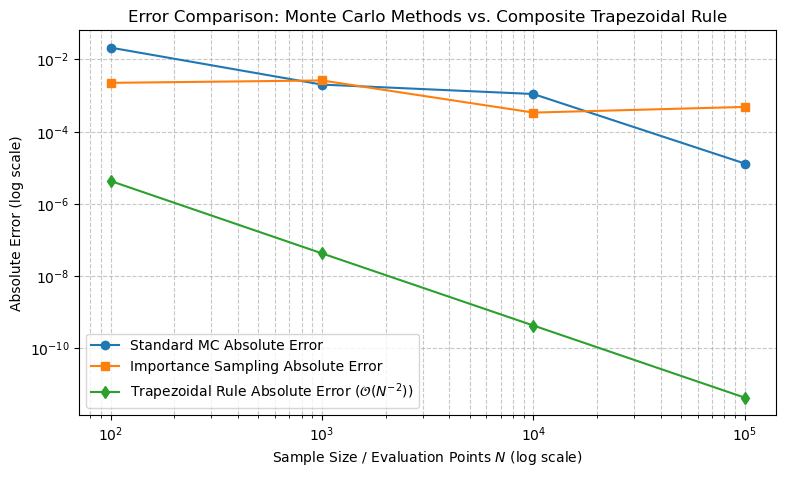

In [18]:
# Part 3: Composite Trapezoidal Rule and Error Comparison Plot
trap_errors = []
mc_errors = [res[5] for res in mc_results]
is_errors = [res[5] for res in is_results]

print("--- Composite Trapezoidal Rule Absolute Errors ---")
print(f"{'N':<8} | {'Trapezoidal Abs Error':<22}")
print("-" * 35)

for n in N_values:
    x_grid = np.linspace(0, 1, n)
    y_grid = 1.0 / (1.0 + x_grid**2)
    approx = np.trapezoid(y_grid, x_grid)
    abs_err = abs(approx - true_integral)
    trap_errors.append(abs_err)
    print(f"{n:<8} | {abs_err:<22.2e}")

# Log-log comparison plot of absolute errors
plt.figure(figsize=(9, 5))
plt.loglog(N_values, mc_errors, 'o-', label='Standard MC Absolute Error')
plt.loglog(N_values, is_errors, 's-', label='Importance Sampling Absolute Error')
plt.loglog(N_values, trap_errors, 'd-', label='Trapezoidal Rule Absolute Error ($\mathcal{O}(N^{-2})$)')
plt.xlabel('Sample Size / Evaluation Points $N$ (log scale)')
plt.ylabel('Absolute Error (log scale)')
plt.title('Error Comparison: Monte Carlo Methods vs. Composite Trapezoidal Rule')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()

In [19]:
import sys
import numpy as np
import matplotlib
import scipy

print("--- Environment & Package Versions ---")
print(f"Python version:    {sys.version.split()[0]}")
print(f"NumPy version:     {np.__version__}")
print(f"Matplotlib version:{matplotlib.__version__}")
print(f"SciPy version:     {scipy.__version__}")

--- Environment & Package Versions ---
Python version:    3.13.9
NumPy version:     2.3.5
Matplotlib version:3.10.6
SciPy version:     1.16.3
